In [ ]:
# import libraries and configure paths

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Dataset paths
BASE_DIR = Path("..")

TRAIN_PATH = BASE_DIR / "datasets" / "train"
TEST_PATH = BASE_DIR / "datasets" / "student_test"

# Results directory
RESULTS_PATH = BASE_DIR / "results" / "eda"
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

# Directory for report-ready plots
PLOTS_PATH = BASE_DIR / "results" / "plots"
PLOTS_PATH.mkdir(parents=True, exist_ok=True)

print("Training path exists:", TRAIN_PATH.exists())
print("Student-test path exists:", TEST_PATH.exists())
print("Results directory:", RESULTS_PATH)
print("Plots directory:", PLOTS_PATH)

In [ ]:
# count trips

train_trips = sorted(
    [p for p in TRAIN_PATH.iterdir() if p.is_dir()]
)

test_trips = sorted(
    [p for p in TEST_PATH.iterdir() if p.is_dir()]
)

print("Training trips:", len(train_trips))
print("Student-test trips:", len(test_trips))
print("Total trips:", len(train_trips) + len(test_trips))

Training trips: 80
Student-test trips: 10
Total trips: 90


## Sample Analysis of trip 00000001

In [ ]:
# inspect one trip

sample_trip = train_trips[0]

print("Sample trip:", sample_trip.name)
print("\nFiles inside:")

for file in sorted(sample_trip.iterdir()):
    print(file.name, "-", file.stat().st_size, "bytes")

Sample trip: 00000001

Files inside:
00000001.arcs - 1948474 bytes
00000001.nodes - 1687371 bytes
00000001.route - 3119 bytes
00000001.track - 40975 bytes


In [ ]:
# inspect the first 5 rows of each file

sample_trip = train_trips[0]
trip_id = sample_trip.name

extensions = [".track", ".nodes", ".arcs", ".route"]

for ext in extensions:
    file_path = sample_trip / f"{trip_id}{ext}"

    print(f"\nFILE: {file_path.name}")

    data = pd.read_csv(
        file_path,
        sep=r"\s+",
        header=None,
        nrows=5
    )

    print(data)
    print("\nShape of first 5 rows:", data.shape)


FILE: 00000001.track
          0          1    2
0  8.595203  49.844053  1.0
1  8.595294  49.844441  2.0
2  8.595352  49.844883  3.0
3  8.595390  49.845379  4.0
4  8.595587  49.845750  5.0

Shape of first 5 rows: (5, 3)

FILE: 00000001.nodes
          0          1
0  8.581679  49.857880
1  8.584637  49.858295
2  8.580173  49.858567
3  8.584392  49.859119
4  8.584935  49.857396

Shape of first 5 rows: (5, 2)

FILE: 00000001.arcs
   0      1
0  0    281
1  0      1
2  0      5
3  1      0
4  1  40750

Shape of first 5 rows: (5, 2)

FILE: 00000001.route
        0
0    2641
1   64973
2  133948
3  133949
4  139208

Shape of first 5 rows: (5, 1)


In [ ]:
# load the complete GPS trajectory

track_file = sample_trip / f"{trip_id}.track"

track = pd.read_csv(
    track_file,
    sep=r"\s+",
    header=None,
    names=["longitude", "latitude", "timestamp"]
)

print("Trip ID:", trip_id)
print("Total GPS observations:", len(track))

print("\nFirst 10 observations:")
display(track.head(10))

print("\nData types:")
print(track.dtypes)

print("\nStatistical summary:")
display(track.describe())

Trip ID: 00000001
Total GPS observations: 1315

First 10 observations:


,longitude,latitude,timestamp
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0
3,8.595390,49.845379,4.0
4,8.595587,49.845750,5.0
5,8.595555,49.846167,6.0
6,8.595744,49.846565,7.0
7,8.595733,49.846931,8.0
8,8.595878,49.847374,9.0
9,8.595849,49.847684,10.0



Data types:
longitude    float64
latitude     float64
timestamp    float64
dtype: object

Statistical summary:


,longitude,latitude,timestamp
count,1315.000000,1315.000000,1315.000000
mean,8.605599,50.088368,661.000760
std,0.016356,0.117561,384.387699
min,8.570524,49.844053,1.000000
25%,8.596061,49.987136,329.500000
50%,8.603564,50.128292,658.000000
75%,8.612624,50.199064,988.500000
max,8.647860,50.211882,1358.000000


In [ ]:
# check for missing values and duplicates

# Missing values
print("Missing values:")
print(track.isnull().sum())

# Duplicate timestamps
print("\nDuplicate timestamps:")
print(track["timestamp"].duplicated().sum())

# Duplicate GPS observations
print("\nDuplicate GPS rows:")
print(track.duplicated().sum())

Missing values:
longitude    0
latitude     0
timestamp    0
dtype: int64

Duplicate timestamps:
0

Duplicate GPS rows:
0


Timestamp gap statistics:


count    1314.000000
mean        1.032725
std         0.446355
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max        16.000000
Name: timestamp, dtype: float64


Number of gaps greater than 5 seconds: 1
Number of zero or negative gaps: 0


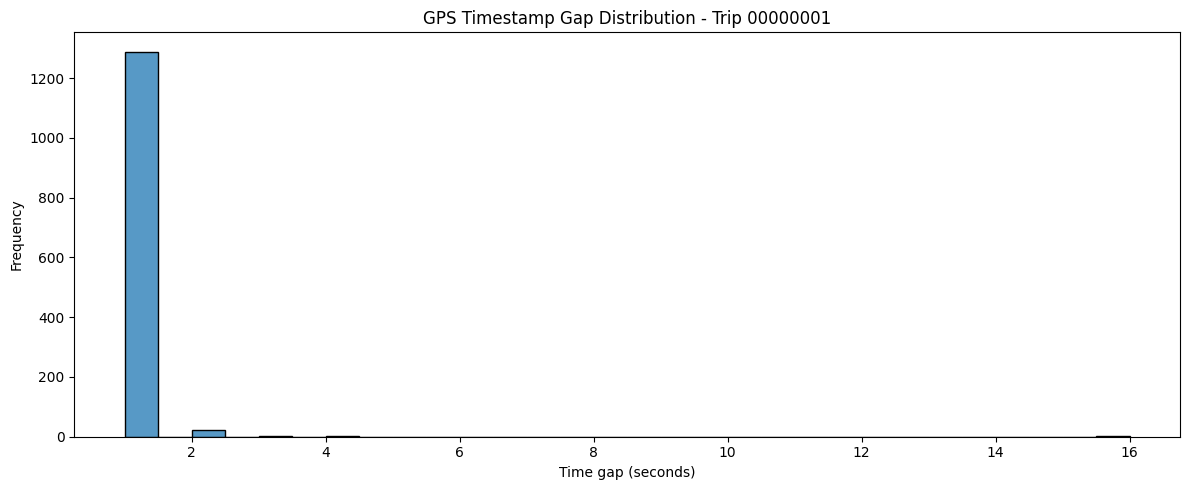

In [ ]:
# calculate time difference between consecutive observations

time_gaps = track["timestamp"].diff().dropna()

print("Timestamp gap statistics:")
display(time_gaps.describe())

print("\nNumber of gaps greater than 5 seconds:",
      (time_gaps > 5).sum())

print("Number of zero or negative gaps:",
      (time_gaps <= 0).sum())

# Plot timestamp gaps
plt.figure(figsize=(12, 5))

sns.histplot(time_gaps, bins=30)

plt.title(f"GPS Timestamp Gap Distribution - Trip {trip_id}")
plt.xlabel("Time gap (seconds)")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    PLOTS_PATH / "sample_trip_timestamp_gaps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# find unusually large timestamp gaps

track["time_gap"] = track["timestamp"].diff()

large_gaps = track[track["time_gap"] > 5]

print("Unusually large GPS gaps:")
display(large_gaps)

# Show the observation immediately before each large gap
for idx in large_gaps.index:
    print(f"\nGap occurs between observations {idx-1} and {idx}:")
    display(track.iloc[[idx-1, idx]])

Unusually large GPS gaps:


,longitude,latitude,timestamp,time_gap
1221,8.582965,50.200698,1250.0,16.0



Gap occurs between observations 1220 and 1221:


,longitude,latitude,timestamp,time_gap
1220,8.583169,50.200578,1234.0,2.0
1221,8.582965,50.200698,1250.0,16.0


## Analysis of All Trips

In [ ]:
# analyise all trips

def analyse_track(trip_path, partition):

    trip_id = trip_path.name
    track_file = trip_path / f"{trip_id}.track"

    track_data = pd.read_csv(
        track_file,
        sep=r"\s+",
        header=None,
        names=["longitude", "latitude", "timestamp"]
    )

    gaps = track_data["timestamp"].diff().dropna()

    return {
        "partition": partition,
        "trip_id": trip_id,
        "gps_observations": len(track_data),

        "missing_values": track_data.isnull().sum().sum(),
        "duplicate_timestamps": track_data["timestamp"].duplicated().sum(),
        "duplicate_rows": track_data.duplicated().sum(),

        "duration": (
            track_data["timestamp"].iloc[-1]
            - track_data["timestamp"].iloc[0]
            if len(track_data) > 1 else 0
        ),

        "mean_gap": gaps.mean(),
        "median_gap": gaps.median(),
        "max_gap": gaps.max(),

        "gaps_over_5_seconds": (gaps > 5).sum(),
        "non_positive_gaps": (gaps <= 0).sum()
    }


# Analyse all training trips
all_results = []

for trip in train_trips:
    all_results.append(analyse_track(trip, "train"))

# Analyse all student-test trips
for trip in test_trips:
    all_results.append(analyse_track(trip, "student_test"))


# Convert results into a DataFrame
df_gps = pd.DataFrame(all_results)

print("GPS analysis completed!")
print("Total trips analysed:", len(df_gps))

display(df_gps.head())

GPS analysis completed!
Total trips analysed: 90


,partition,trip_id,gps_observations,missing_values,duplicate_timestamps,duplicate_rows,duration,mean_gap,median_gap,max_gap,gaps_over_5_seconds,non_positive_gaps
0,train,00000001,1315,0,0,0,1357.000,1.032725,1.0,16.0,1,0
1,train,00000002,7243,0,0,0,8933.156,1.233521,1.0,160.0,78,0
2,train,00000003,821,0,0,0,823.000,1.003659,1.0,2.0,0,0
3,train,00000004,1064,0,0,0,5217.000,4.907808,1.0,51.0,320,0
4,train,00000005,1045,0,0,0,1044.000,1.000000,1.0,1.0,0,0


In [ ]:
# generate dataset-wide statistics

# Summary statistics for each partition

summary = df_gps.groupby("partition").agg({
    "gps_observations": ["count", "mean", "median", "min", "max"],
    "duration": ["mean", "median", "min", "max"],
    "mean_gap": ["mean", "median"],
    "max_gap": ["mean", "max"],
    "gaps_over_5_seconds": "sum",
    "missing_values": "sum",
    "duplicate_timestamps": "sum",
    "duplicate_rows": "sum"
})

display(summary)

gps_observations                                    duration  \
                        count       mean  median  min    max         mean   
partition                                                                   
student_test               10  1916.0000  1420.0  262   3958  2025.000000   
train                      80  2605.2125  1529.0  361  19313  5680.404487   

                                          mean_gap           max_gap  \
                 median    min       max      mean    median    mean   
partition                                                              
student_test  1809.5000  265.0    4000.0  1.090549  1.000677    25.5   
train         1710.0015  451.0  154030.0  5.101888  1.058959  2706.4   

                       gaps_over_5_seconds missing_values  \
                   max                 sum            sum   
partition                                                   
student_test     210.0                  44              0   
train         153064.0                1216              0   

             duplicate_timestamps duplicate_rows  
                              sum            sum  
partition                                         
student_test                    0              0  
train                           0              0

In [ ]:
# save your results

# Save trip-level GPS statistics
df_gps.to_csv(
    RESULTS_PATH / "gps_trip_statistics.csv",
    index=False
)

# Save partition-level summary
summary.to_csv(
    RESULTS_PATH / "gps_partition_summary.csv"
)

print("Saved successfully!")
print("Location:", RESULTS_PATH)

Saved successfully!
Location: ../results/eda


## GPS Summary Visualisations

Visualise GPS observations per trip, trip duration, and timestamp gaps across the training and student-test partitions.

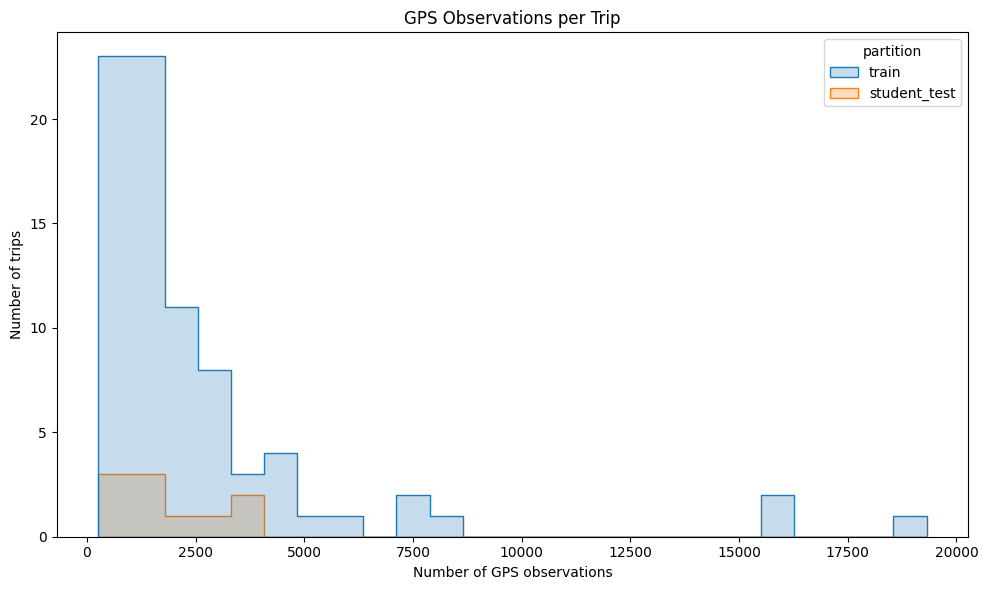

In [ ]:
# plot GPS observations per trip

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_gps,
    x="gps_observations",
    hue="partition",
    bins=25,
    element="step",
    common_norm=False
)

plt.title("GPS Observations per Trip")
plt.xlabel("Number of GPS observations")
plt.ylabel("Number of trips")
plt.tight_layout()

plt.savefig(
    PLOTS_PATH / "points_per_trip.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

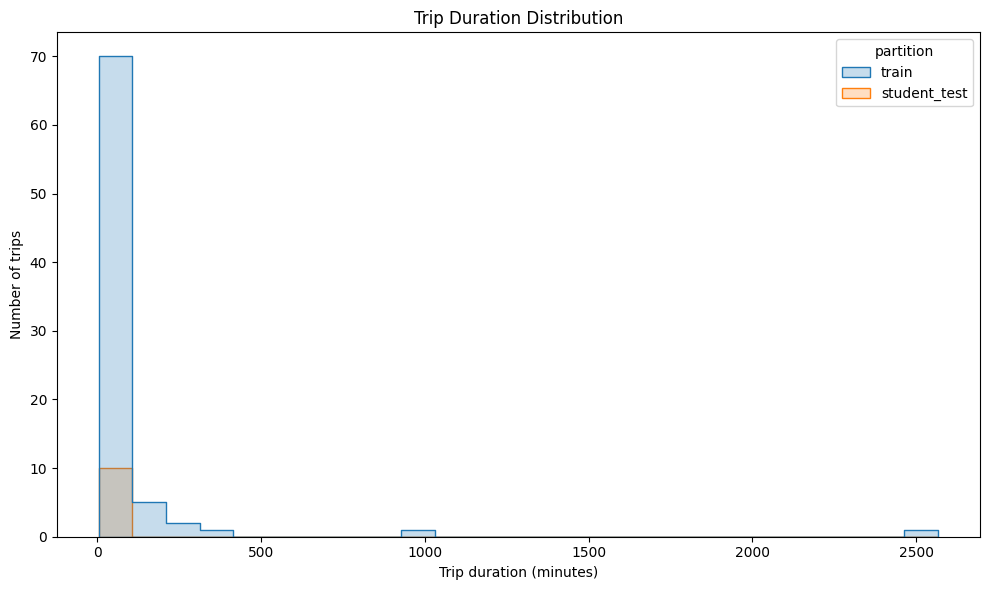

In [ ]:
# plot trip duration distribution

df_gps["duration_minutes"] = df_gps["duration"] / 60

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_gps,
    x="duration_minutes",
    hue="partition",
    bins=25,
    element="step",
    common_norm=False
)

plt.title("Trip Duration Distribution")
plt.xlabel("Trip duration (minutes)")
plt.ylabel("Number of trips")
plt.tight_layout()

plt.savefig(
    PLOTS_PATH / "trip_duration_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

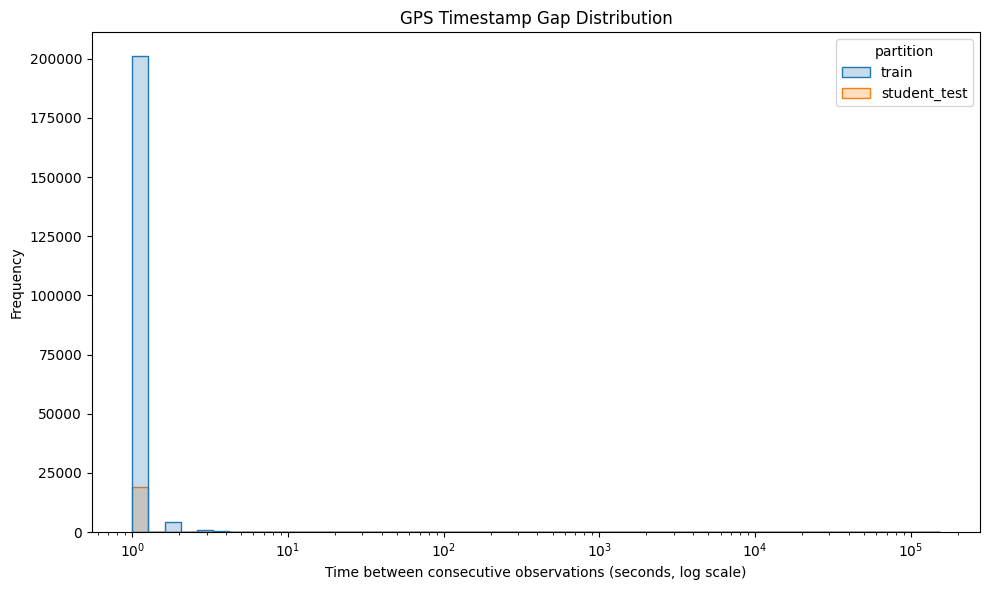

Total positive timestamp gaps: 227487


In [ ]:
# plot timestamp gaps across all trips

gap_results = []

for partition, trips in [
    ("train", train_trips),
    ("student_test", test_trips)
]:
    for trip_path in trips:

        trip_id = trip_path.name

        track_data = pd.read_csv(
            trip_path / f"{trip_id}.track",
            sep=r"\s+",
            header=None,
            names=["longitude", "latitude", "timestamp"]
        )

        gaps = track_data["timestamp"].diff().dropna()

        for gap in gaps:
            if gap > 0:
                gap_results.append({
                    "partition": partition,
                    "gap_seconds": gap
                })

df_gaps = pd.DataFrame(gap_results)

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_gaps,
    x="gap_seconds",
    hue="partition",
    bins=50,
    element="step",
    common_norm=False,
    log_scale=True
)

plt.title("GPS Timestamp Gap Distribution")
plt.xlabel("Time between consecutive observations (seconds, log scale)")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    PLOTS_PATH / "timestamp_gap_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Total positive timestamp gaps:", len(df_gaps))

## GPS Timestamp Anomaly Investigation

Identify trips with unusually large timestamp gaps and inspect
the GPS observations surrounding those gaps.

In [ ]:
# find the trips with the largest gaps

# Rank trips by their maximum timestamp gap

top_gap_trips = df_gps.sort_values(
    by="max_gap",
    ascending=False
)

display(
    top_gap_trips[
        [
            "trip_id",
            "partition",
            "gps_observations",
            "duration",
            "mean_gap",
            "max_gap",
            "gaps_over_5_seconds"
        ]
    ].head(10)
)

,trip_id,partition,gps_observations,duration,mean_gap,max_gap,gaps_over_5_seconds
72,00000090,train,536,154030.0,287.906542,153064.0,20
61,00000078,train,2909,57836.0,19.888583,52810.0,124
55,00000069,train,2067,5558.0,2.690223,2658.0,2
16,00000021,train,15783,18605.0,1.178875,2161.0,2
8,00000011,train,2828,3735.0,1.321189,909.0,1
34,00000042,train,7739,12377.0,1.599509,670.0,45
64,00000081,train,3224,8481.0,2.631399,536.0,129
18,00000024,train,801,1541.0,1.926250,458.0,4
36,00000044,train,546,980.0,1.798165,341.0,2
67,00000084,train,16031,16524.0,1.030817,312.0,4


In [ ]:
# inspect the largest gap in the worst trip

# Select the trip with the largest timestamp gap

worst_trip_id = top_gap_trips.iloc[0]["trip_id"]
worst_partition = top_gap_trips.iloc[0]["partition"]

data_path = (
    TRAIN_PATH if worst_partition == "train"
    else TEST_PATH
)

worst_trip_path = data_path / worst_trip_id

# Load the GPS data
worst_track = pd.read_csv(
    worst_trip_path / f"{worst_trip_id}.track",
    sep=r"\s+",
    header=None,
    names=["longitude", "latitude", "timestamp"]
)

# Calculate timestamp differences
worst_track["time_gap"] = (
    worst_track["timestamp"].diff()
)

# Find the largest gap
largest_gap_index = worst_track["time_gap"].idxmax()

print("Trip:", worst_trip_id)
print("Partition:", worst_partition)
print("Largest gap:", worst_track.loc[largest_gap_index, "time_gap"], "seconds")

# Display observations before and after the gap
display(
    worst_track.iloc[
        max(0, largest_gap_index - 2):
        largest_gap_index + 3
    ]
)

Trip: 00000090
Partition: train
Largest gap: 153064.0 seconds


,longitude,latitude,timestamp,time_gap
533,10.445839,51.621247,962.0,4.0
534,10.445741,51.621282,970.0,8.0
535,10.445779,51.621300,154034.0,153064.0


In [ ]:
# compare the final observations of the two most anomalous trips

for trip_id in ["00000090", "00000078"]:

    trip_path = TRAIN_PATH / trip_id

    track_data = pd.read_csv(
        trip_path / f"{trip_id}.track",
        sep=r"\s+",
        header=None,
        names=["longitude", "latitude", "timestamp"]
    )

    track_data["time_gap"] = (
        track_data["timestamp"].diff()
    )

    largest_gap_idx = track_data["time_gap"].idxmax()

    print(f"\n{'='*45}")
    print(f"TRIP: {trip_id}")
    print(f"{'='*45}")

    print("Total observations:", len(track_data))

    print("\nObservations surrounding largest gap:")

    start = max(0, largest_gap_idx - 3)
    end = min(len(track_data), largest_gap_idx + 4)

    display(track_data.iloc[start:end])


TRIP: 00000090
Total observations: 536

Observations surrounding largest gap:


,longitude,latitude,timestamp,time_gap
532,10.445810,51.621172,958.0,4.0
533,10.445839,51.621247,962.0,4.0
534,10.445741,51.621282,970.0,8.0
535,10.445779,51.621300,154034.0,153064.0



TRIP: 00000078
Total observations: 2909

Observations surrounding largest gap:


,longitude,latitude,timestamp,time_gap
0,3.595470,44.321728,3.0,NaN
1,3.595384,44.321698,4.0,1.0
2,3.595358,44.321711,52814.0,52810.0
3,3.595465,44.321734,52834.0,20.0
4,3.595355,44.321760,52841.0,7.0
5,3.595393,44.321755,52842.0,1.0


In [ ]:
# investigate geographical movement across large timestamp gaps

import numpy as np

def haversine_distance(lon1, lat1, lon2, lat2):

    R = 6371000  # Earth radius in metres

    lon1, lat1, lon2, lat2 = map(
        np.radians,
        [lon1, lat1, lon2, lat2]
    )

    dlon = lon2 - lon1
    dlat = lat2 - lat1

    a = (
        np.sin(dlat / 2)**2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2)**2
    )

    return 2 * R * np.arcsin(np.sqrt(a))


for trip_id in ["00000090", "00000078"]:

    trip_path = TRAIN_PATH / trip_id

    track_data = pd.read_csv(
        trip_path / f"{trip_id}.track",
        sep=r"\s+",
        header=None,
        names=["longitude", "latitude", "timestamp"]
    )

    track_data["time_gap"] = (
        track_data["timestamp"].diff()
    )

    gap_idx = track_data["time_gap"].idxmax()

    previous = track_data.iloc[gap_idx - 1]
    current = track_data.iloc[gap_idx]

    distance = haversine_distance(
        previous["longitude"],
        previous["latitude"],
        current["longitude"],
        current["latitude"]
    )

    print(f"\nTrip: {trip_id}")
    print("Time gap:", current["time_gap"], "seconds")
    print("Distance across gap:", round(distance, 2), "metres")


Trip: 00000090
Time gap: 153064.0 seconds
Distance across gap: 3.3 metres

Trip: 00000078
Time gap: 52810.0 seconds
Distance across gap: 2.52 metres


### Findings

Analysis of all 90 trips revealed irregularities in GPS timestamp intervals.

Key findings:

- The majority of GPS observations have approximately one-second sampling intervals.
- Several training trips contain unusually large timestamp gaps.
- Trip `00000090` contains the largest observed gap of 153,064 seconds (approximately 42.5 hours).
- The gap occurs between the final two GPS observations.
- The geographic coordinates of these observations differ by only approximately 3 metres.
- Trip `00000078` also exhibits an unusually large gap of 52,810 seconds.

**Preliminary interpretation:** These observations may indicate recording interruptions or timestamp discontinuities. Further investigation is required before determining whether the affected observations should be excluded or handled during preprocessing.

## Geographical Exploratory Data Analysis

Analyse the geographical distribution of GPS observations
across training and student-test trips.

Investigate:
- Longitude and latitude distributions
- Geographic boundaries
- Spatial outliers
- Trip-level geographic coverage

In [ ]:
# analysis geographical data across all trips

geo_results = []

for partition, trips in [
    ("train", train_trips),
    ("student_test", test_trips)
]:

    for trip_path in trips:

        trip_id = trip_path.name

        track = pd.read_csv(
            trip_path / f"{trip_id}.track",
            sep=r"\s+",
            header=None,
            names=["longitude", "latitude", "timestamp"]
        )

        geo_results.append({
            "partition": partition,
            "trip_id": trip_id,

            "min_longitude": track["longitude"].min(),
            "max_longitude": track["longitude"].max(),

            "min_latitude": track["latitude"].min(),
            "max_latitude": track["latitude"].max(),

            "mean_longitude": track["longitude"].mean(),
            "mean_latitude": track["latitude"].mean(),

            "longitude_range": (
                track["longitude"].max()
                - track["longitude"].min()
            ),

            "latitude_range": (
                track["latitude"].max()
                - track["latitude"].min()
            )
        })

df_geo = pd.DataFrame(geo_results)

print("Geographical analysis completed!")
print("Trips analysed:", len(df_geo))

display(df_geo.head())

Geographical analysis completed!
Trips analysed: 90


,partition,trip_id,min_longitude,max_longitude,min_latitude,max_latitude,mean_longitude,mean_latitude,longitude_range,latitude_range
0,train,00000001,8.570524,8.647860,49.844053,50.211882,8.605599,50.088368,0.077336,0.367829
1,train,00000002,10.999961,11.050902,47.658344,47.695459,11.032568,47.683925,0.050941,0.037115
2,train,00000003,37.154202,37.201595,55.977135,56.007585,37.177362,55.987684,0.047393,0.030450
3,train,00000004,12.342280,12.459615,52.590308,52.718960,12.424218,52.641499,0.117335,0.128652
4,train,00000005,35.485577,35.544315,49.357581,49.613085,35.503261,49.486068,0.058738,0.255504


In [ ]:
# compare geographical boundaries

# Geographic summary by partition

geo_summary = df_geo.groupby("partition").agg({
    "min_longitude": "min",
    "max_longitude": "max",
    "min_latitude": "min",
    "max_latitude": "max",

    "longitude_range": ["mean", "max"],
    "latitude_range": ["mean", "max"]
})

display(geo_summary)

min_longitude max_longitude min_latitude max_latitude  \
                       min           max          min          max   
partition                                                            
student_test    -93.424337     77.271115    42.645529    61.699590   
train          -100.418538    137.237029   -34.640291    61.267258   

             longitude_range           latitude_range            
                        mean       max           mean       max  
partition                                                        
student_test        0.149993  0.715028       0.083058  0.241213  
train               0.187278  1.103908       0.107771  0.678126

### Geographical Visualisations

Visualise geographical coordinate distributions, GPS coverage, and sample trip trajectories.

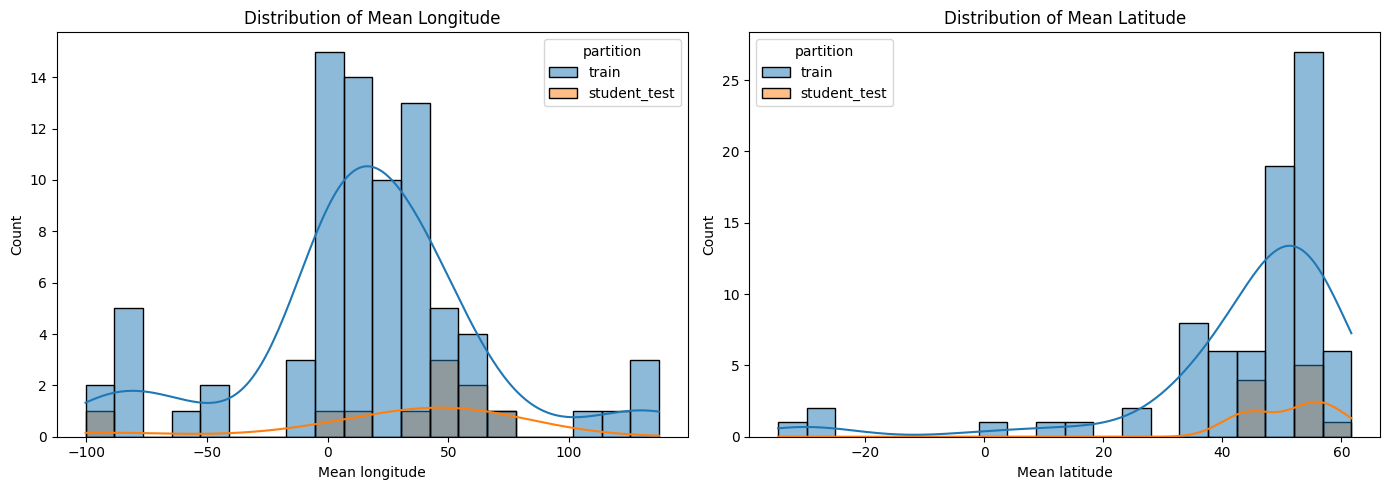

In [ ]:
# plot distribution of mean longitude and latitude

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df_geo,
    x="mean_longitude",
    hue="partition",
    bins=20,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of Mean Longitude")
axes[0].set_xlabel("Mean longitude")

sns.histplot(
    data=df_geo,
    x="mean_latitude",
    hue="partition",
    bins=20,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Distribution of Mean Latitude")
axes[1].set_xlabel("Mean latitude")

plt.tight_layout()

plt.savefig(
    PLOTS_PATH / "geographical_coordinate_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

/var/folders/ms/k4cn6c4j3pb1myndb35p4cbr0000gn/T/ipykernel_16059/3530487903.py:69: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(
/Users/maayamohan/Library/Python/3.13/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


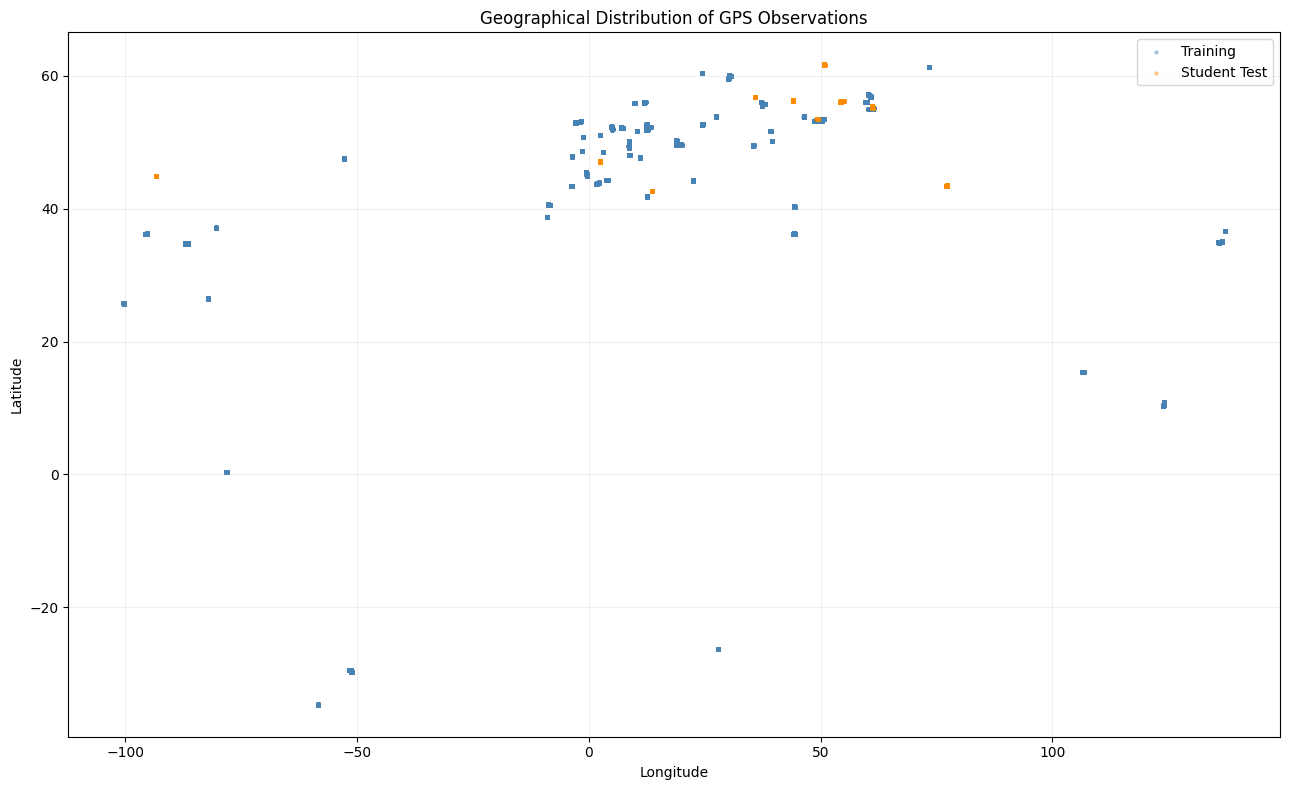

Total GPS points plotted: 128813


In [ ]:
# plot geographical distribution of GPS observations

partitions = {
    "Training": TRAIN_PATH,
    "Student Test": TEST_PATH
}

gps_data = []

MAX_POINTS_PER_TRIP = 2000

for partition_name, partition_path in partitions.items():

    trips = sorted([
        p for p in partition_path.iterdir()
        if p.is_dir()
    ])

    for trip in trips:

        trip_file = trip / f"{trip.name}.track"

        if not trip_file.exists():
            continue

        data = pd.read_csv(
            trip_file,
            sep=r"\s+",
            header=None,
            names=["longitude", "latitude", "timestamp"]
        )

        if len(data) > MAX_POINTS_PER_TRIP:
            data = data.sample(
                n=MAX_POINTS_PER_TRIP,
                random_state=42
            )

        data["partition"] = partition_name
        gps_data.append(data)

gps_df = pd.concat(gps_data, ignore_index=True)

plt.figure(figsize=(13, 8))

for partition_name, color in [
    ("Training", "steelblue"),
    ("Student Test", "darkorange")
]:

    subset = gps_df[gps_df["partition"] == partition_name]

    plt.scatter(
        subset["longitude"],
        subset["latitude"],
        s=5,
        alpha=0.35,
        label=partition_name,
        color=color
    )

plt.title("Geographical Distribution of GPS Observations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    PLOTS_PATH / "geographical_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Total GPS points plotted:", len(gps_df))

/var/folders/ms/k4cn6c4j3pb1myndb35p4cbr0000gn/T/ipykernel_16059/1497480086.py:49: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


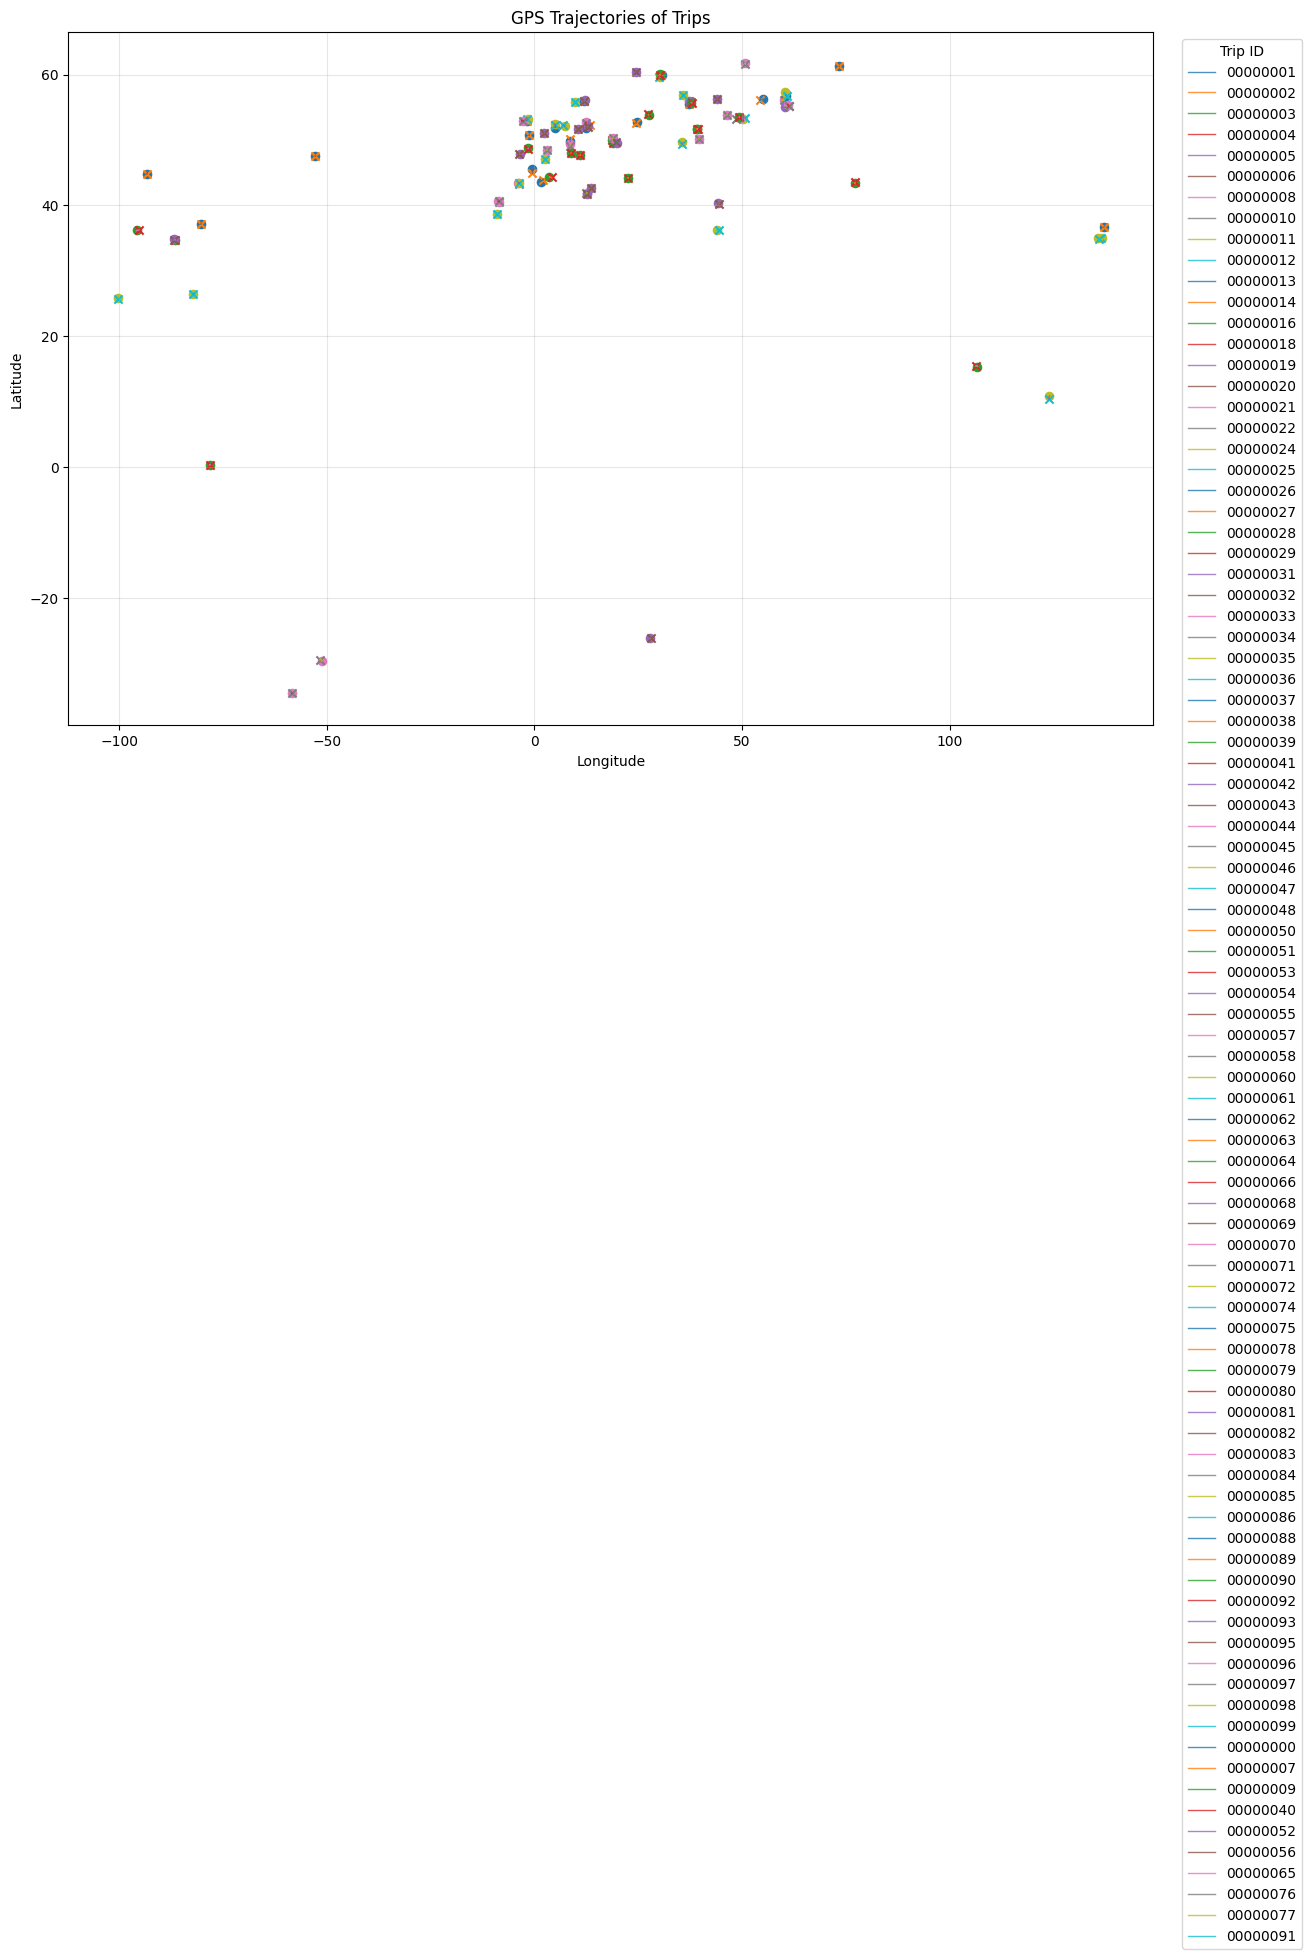

In [ ]:
# plot GPS trajectories of trips

plt.figure(figsize=(14, 9))

all_trips = train_trips + test_trips

for trip in all_trips:

    trip_file = trip / f"{trip.name}.track"

    data = pd.read_csv(
        trip_file,
        sep=r"\s+",
        header=None,
        names=["longitude", "latitude", "timestamp"]
    )

    data = data.sort_values("timestamp")

    plt.plot(
        data["longitude"],
        data["latitude"],
        linewidth=1,
        alpha=0.8,
        label=trip.name
    )

    # Starting point
    plt.scatter(
        data["longitude"].iloc[0],
        data["latitude"].iloc[0],
        marker="o",
        s=35
    )

    # Ending point
    plt.scatter(
        data["longitude"].iloc[-1],
        data["latitude"].iloc[-1],
        marker="x",
        s=35
    )

plt.title("GPS Trajectories of Trips")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Trip ID", bbox_to_anchor=(1.02, 1))
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOTS_PATH / "trajectories.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# save the geographical analysis

df_geo.to_csv(
    RESULTS_PATH / "gps_geographical_statistics.csv",
    index=False
)

geo_summary.to_csv(
    RESULTS_PATH / "gps_geographical_summary.csv"
)

print("Geographical statistics saved!")

Geographical statistics saved!


## Road Network Exploratory Data Analysis

Analyse the road-network structure across the training and student-test partitions.

This section examines:
- Number of nodes and arcs per trip
- Invalid arc references
- Isolated nodes
- Weakly connected components
- Size of the largest connected component

In [ ]:
# analyse road-network statistics across all trips

from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

def analyse_road_network(trip_path, partition):

    trip_id = trip_path.name

    # Load road-network nodes
    nodes = pd.read_csv(
        trip_path / f"{trip_id}.nodes",
        sep=r"\s+",
        header=None,
        names=["longitude", "latitude"]
    )

    # Load road-network arcs
    arcs = pd.read_csv(
        trip_path / f"{trip_id}.arcs",
        sep=r"\s+",
        header=None,
        names=["from_node", "to_node"]
    )

    node_count = len(nodes)
    arc_count = len(arcs)

    # Node IDs correspond to zero-based row indices in .nodes
    source = pd.to_numeric(
        arcs["from_node"], errors="coerce"
    ).to_numpy()

    target = pd.to_numeric(
        arcs["to_node"], errors="coerce"
    ).to_numpy()

    # Identify valid node references
    valid = (
        np.isfinite(source)
        & np.isfinite(target)
        & (source == np.floor(source))
        & (target == np.floor(target))
        & (source >= 0)
        & (target >= 0)
        & (source < node_count)
        & (target < node_count)
    )

    invalid_arcs = int((~valid).sum())

    source = source[valid].astype(int)
    target = target[valid].astype(int)

    valid_arc_count = len(source)

    # Calculate node degrees
    # A node is isolated if it has no incoming or outgoing connections.
    degree = np.zeros(node_count, dtype=int)

    np.add.at(degree, source, 1)
    np.add.at(degree, target, 1)

    isolated_nodes = int(np.sum(degree == 0))

    # Build an undirected graph for weak connectivity analysis.
    # This treats an arc in either direction as a connection.
    graph = coo_matrix(
        (
            np.ones(2 * valid_arc_count),
            (
                np.concatenate([source, target]),
                np.concatenate([target, source])
            )
        ),
        shape=(node_count, node_count)
    ).tocsr()

    # Find connected components
    if node_count > 0:

        component_count, labels = connected_components(
            graph,
            directed=False,
            return_labels=True
        )

        component_sizes = np.bincount(labels)

        largest_component_size = int(component_sizes.max())

    else:
        component_count = 0
        largest_component_size = 0

    largest_component_fraction = (
        largest_component_size / node_count
        if node_count > 0 else 0
    )

    return {
        "partition": partition,
        "trip_id": trip_id,
        "node_count": node_count,
        "arc_count": arc_count,
        "valid_arc_count": valid_arc_count,
        "invalid_arcs": invalid_arcs,
        "isolated_nodes": isolated_nodes,
        "connected_components": int(component_count),
        "largest_component_size": largest_component_size,
        "largest_component_fraction": largest_component_fraction
    }


# Run analysis on training and student-test partitions

network_results = []

for partition, trips in [
    ("train", train_trips),
    ("student_test", test_trips)
]:

    for trip_path in trips:

        result = analyse_road_network(
            trip_path,
            partition
        )

        network_results.append(result)


df_network = pd.DataFrame(network_results)

print("Road-network analysis completed!")
print("Total trips analysed:", len(df_network))

display(df_network.head())

Road-network analysis completed!
Total trips analysed: 90


,partition,trip_id,node_count,arc_count,valid_arc_count,invalid_arcs,isolated_nodes,connected_components,largest_component_size,largest_component_fraction
0,train,00000001,88809,165790,165790,0,0,175,86854,0.977986
1,train,00000002,7936,16139,16139,0,0,14,7750,0.976562
2,train,00000003,9138,18028,18028,0,0,42,8625,0.943861
3,train,00000004,7350,15499,15499,0,0,12,7254,0.986939
4,train,00000005,898,1579,1579,0,0,3,888,0.988864


In [ ]:
# summarise road-network statistics by partition

network_summary = df_network.groupby("partition").agg(
    total_trips=("trip_id", "count"),

    mean_nodes=("node_count", "mean"),
    median_nodes=("node_count", "median"),

    mean_arcs=("arc_count", "mean"),
    median_arcs=("arc_count", "median"),

    total_isolated_nodes=("isolated_nodes", "sum"),
    mean_isolated_nodes=("isolated_nodes", "mean"),

    mean_connected_components=("connected_components", "mean"),
    max_connected_components=("connected_components", "max"),

    mean_largest_component_size=("largest_component_size", "mean"),
    mean_largest_component_fraction=("largest_component_fraction", "mean"),

    total_invalid_arcs=("invalid_arcs", "sum")
).reset_index()

display(network_summary)

,partition,total_trips,mean_nodes,median_nodes,mean_arcs,median_arcs,total_isolated_nodes,mean_isolated_nodes,mean_connected_components,max_connected_components,mean_largest_component_size,mean_largest_component_fraction,total_invalid_arcs
0,student_test,10,9068.9000,6596.5,18504.1,13145.0,0,0.0,22.7000,100,8749.900,0.963918,0
1,train,80,24168.5625,9608.0,48461.3,19526.5,0,0.0,39.0125,421,23585.075,0.968963,0


In [ ]:
# save per-trip road-network statistics

df_network.to_csv(
    RESULTS_PATH / "road_network_statistics.csv",
    index=False
)

# Save partition-level road-network summary

network_summary.to_csv(
    RESULTS_PATH / "road_network_summary.csv",
    index=False
)

print("Road-network CSV files saved successfully!")

Road-network CSV files saved successfully!


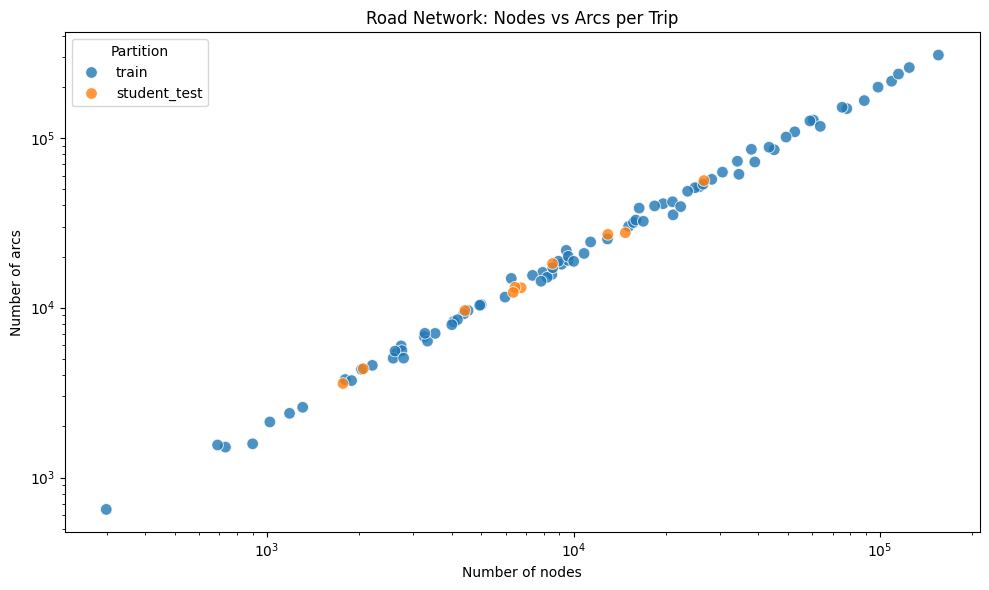

In [ ]:
# plot number of road-network nodes versus arcs per trip

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_network,
    x="node_count",
    y="arc_count",
    hue="partition",
    s=70,
    alpha=0.8
)

plt.title("Road Network: Nodes vs Arcs per Trip")
plt.xlabel("Number of nodes")
plt.ylabel("Number of arcs")
plt.xscale("log")
plt.yscale("log")
plt.legend(title="Partition")
plt.tight_layout()

plt.savefig(
    PLOTS_PATH / "road_network_nodes_vs_arcs.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

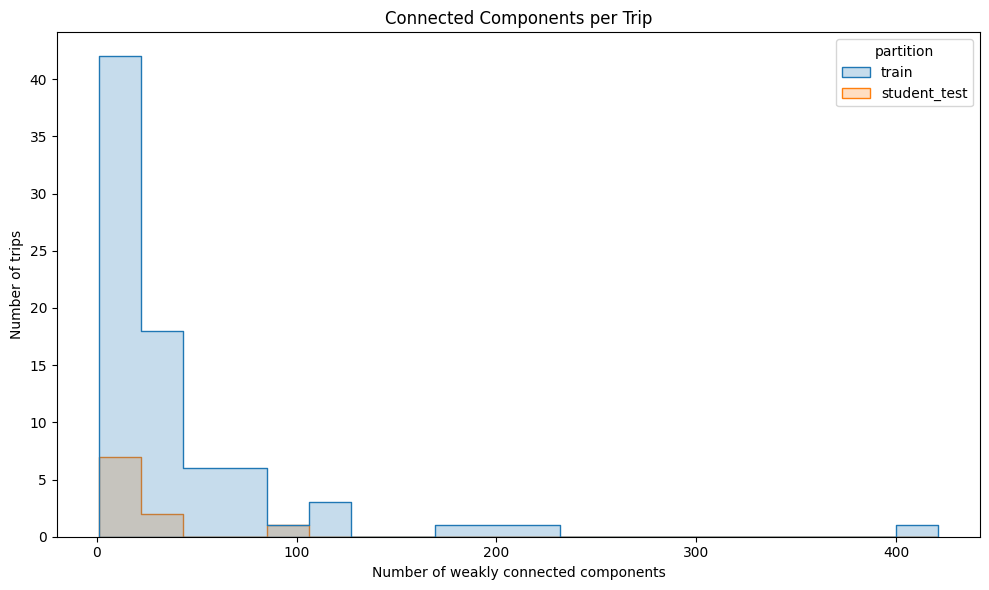

In [ ]:
# plot connected components per trip

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_network,
    x="connected_components",
    hue="partition",
    bins=20,
    element="step",
    common_norm=False
)

plt.title("Connected Components per Trip")
plt.xlabel("Number of weakly connected components")
plt.ylabel("Number of trips")
plt.tight_layout()

plt.savefig(
    PLOTS_PATH / "road_network_components.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

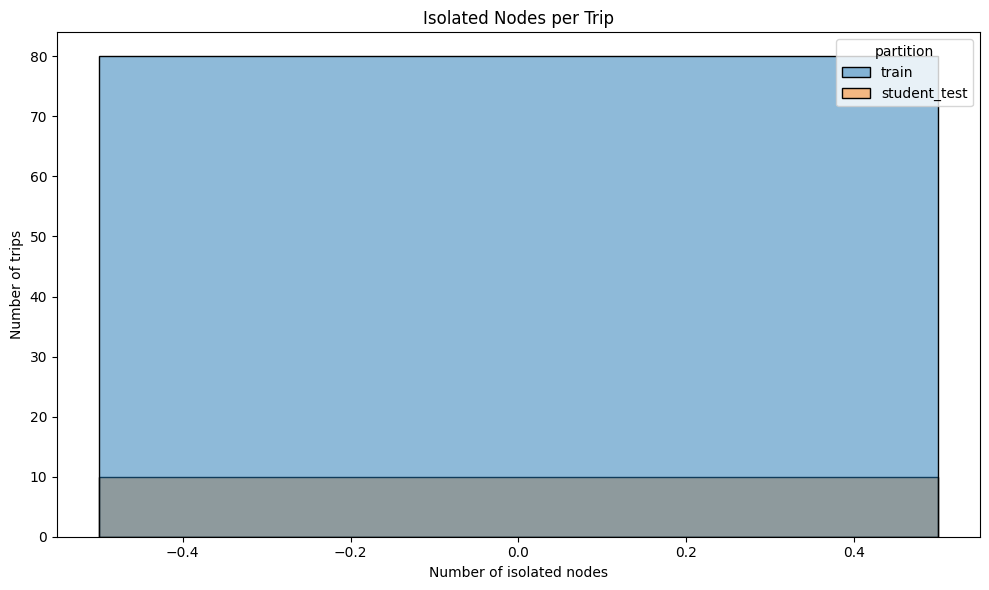

In [ ]:
# plot isolated nodes per trip

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_network,
    x="isolated_nodes",
    hue="partition",
    discrete=True,
    element="bars",
    common_norm=False
)

plt.title("Isolated Nodes per Trip")
plt.xlabel("Number of isolated nodes")
plt.ylabel("Number of trips")
plt.tight_layout()

plt.savefig(
    PLOTS_PATH / "road_network_isolated_nodes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

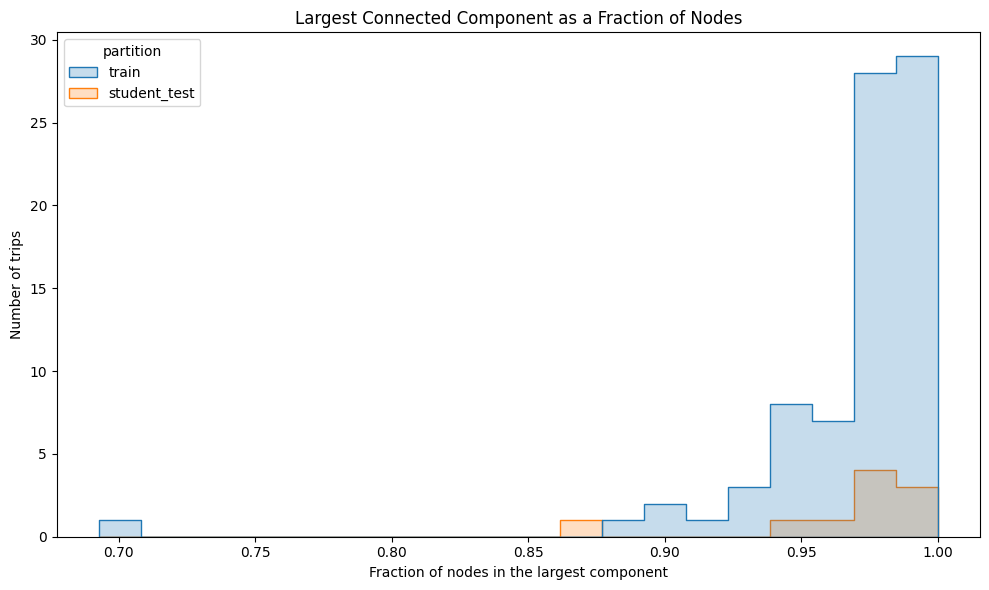

In [ ]:
# plot largest connected component fraction

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_network,
    x="largest_component_fraction",
    hue="partition",
    bins=20,
    element="step",
    common_norm=False
)

plt.title("Largest Connected Component as a Fraction of Nodes")
plt.xlabel("Fraction of nodes in the largest component")
plt.ylabel("Number of trips")
plt.tight_layout()

plt.savefig(
    PLOTS_PATH / "road_network_largest_component.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()